# 07 — Modernized presets: training `BASELINE_V2` and `FINEGRAINED`

Journal entry [034](../journey_of_a_model/034-modernized-presets.md) *defined*
`BASELINE_V2` (= `BASELINE` + QK-norm + sigmoid routing + width-aware init) and
`FINEGRAINED` (= `BASELINE_V2` + DeepSeekMoE 8→32 expert segmentation) but did
**not** train them head-to-head — it argued from the per-change evidence in
entries 022 / 025 / 023 and left the bake-off to "the ablation study's job".

This notebook runs that bake-off: a real, **compute-matched** comparison of
`BASELINE`, `BASELINE_V2` and `FINEGRAINED` on one identical fixed token slice
and one identical token budget, using the project's own
`qwenmoe.train.compare.run_comparison` (the task-16 multi-seed path), then plots
the loss curves and pulls real forward-pass traces from the trained checkpoints.

**Scope / honesty note.** The `BASELINE` family is *designed* for a from-scratch
BPE-4096 tokenizer on TinyStories (≈23.5M params — see entry 034). That
tokenizer's pure-Python merge loop takes minutes per megabyte, and the
32-expert `FINEGRAINED` forward hits a pathological Metal kernel (~13× slower on
`mps` than `cpu`). So this run uses the **fast tier**: char-level
tiny-Shakespeare (vocab ≈ 65), on **CPU**, exactly like
`scripts/run_ablation_study.py --smoke`. The three architectural changes under
test — QK-norm, sigmoid routing, width-aware init, expert granularity — are all
**independent of the vocabulary**, so the comparison is still valid; only the
absolute loss scale and the embedding/LM-head parameter count differ from the
BPE regime. The BPE-4096 parameter counts from entry 034 are reproduced below
for reference.

The narrated write-up of these numbers is journal entry
[035](../journey_of_a_model/035-modernized-presets-training-run.md).

In [1]:
from pathlib import Path
import os, json, math, dataclasses, statistics, time, logging

repo_root = Path.cwd()
while not (repo_root / "pyproject.toml").exists():
    repo_root = repo_root.parent
os.chdir(repo_root)
print("repo root:", repo_root)

# Stream Trainer's per-step logs so a long training cell is never silent for
# minutes at a time (a silent cell can make nbconvert's client think the
# kernel died and re-execute it — which double-writes every run's log).
logging.basicConfig(level=logging.INFO, format="%(asctime)s  %(message)s", force=True)

import numpy as np
import torch
import matplotlib.pyplot as plt

import configs.presets as presets
from qwenmoe.config import DataConfig, TrainConfig
from qwenmoe.data.download import prepared_data_dir
from qwenmoe.model.transformer import QwenMoEModel
from qwenmoe.tokenizer.base import build_tokenizer
from qwenmoe.train.compare import run_comparison
from qwenmoe.train.scaling import chinchilla_budget, count_params, moe_budget_note
from qwenmoe.viz.common import capture_trace

FIG_DIR = repo_root / "journey_of_a_model" / "figures" / "035"
FIG_DIR.mkdir(parents=True, exist_ok=True)
RUN_DIR = repo_root / "runs" / "modernized_presets"

plt.rcParams.update({"figure.dpi": 110, "savefig.bbox": "tight", "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 10})
COLORS = {"BASELINE": "#6b7280", "BASELINE_V2": "#2563eb", "FINEGRAINED": "#dc2626"}
VARIANTS = ["BASELINE", "BASELINE_V2", "FINEGRAINED"]
print("torch", torch.__version__)

repo root: /Users/sjoseph/Documents/Study/training-my-moe


torch 2.13.0


## 1. The three presets

`BASELINE_V2` and `FINEGRAINED` are two `dataclasses.replace` calls off
`BASELINE` in `configs/presets.py`. The deltas:

| preset | qk_norm | router_scoring | init_std | n_routed_experts | d_ff | top_k | n_shared_experts |
|---|---|---|---|---|---|---|---|
| `BASELINE` | `False` | `softmax` | `0.02` | 8 | 512 | 2 | 1 |
| `BASELINE_V2` | **`True`** | **`sigmoid`** | **`√(2/5d)≈0.0395`** | 8 | 512 | 2 | 1 |
| `FINEGRAINED` | `True` | `sigmoid` | `≈0.0395` | **32** | **128** | **8** | 1 |

`FINEGRAINED` holds the routed-FFN parameter budget constant (`32×128 == 8×512`)
and the per-token active routed FFN constant (`8×128 == 2×512`); only the router
(`n_experts·d_model`) grows and the single shared expert narrows to `d_ff=128`.

In [2]:
data_config = DataConfig(
    corpus="tiny_shakespeare", tokenizer_type="char",
    cache_dir=Path(".cache/data"),
    fixed_slice_tokens=1_000_000, fixed_slice_seed=0,
)
prep = prepared_data_dir(data_config)
if not (prep / "tokens.pt").exists():
    from scripts.prepare_data import prepare_data
    prepare_data(dataclasses.replace(data_config, fixed_slice_tokens=None))

tok = build_tokenizer(data_config); tok.load(prep / "tokenizer.json")
VOCAB = tok.vocab_size
all_tokens = torch.load(prep / "tokens.pt", weights_only=True)
print(f"char tiny-Shakespeare: {all_tokens.numel():,} tokens, vocab_size = {VOCAB}")
print(f"fixed slice for every variant: {data_config.fixed_slice_tokens:,} tokens "
      f"(seed {data_config.fixed_slice_seed}); tail 10% held out for validation\n")

def param_row(name, vocab):
    cfg = dataclasses.replace(getattr(presets, name), vocab_size=vocab, max_seq_len=256)
    bd = count_params(QwenMoEModel(cfg))
    return cfg, bd

print(f"{'preset':<13}{'total':>13}{'active/tok':>13}{'sparsity':>10}   (this run, vocab_size={VOCAB})")
cfgs = {}
for name in VARIANTS:
    cfg, bd = param_row(name, VOCAB)
    cfgs[name] = cfg
    print(f"{name:<13}{bd.total:>13,}{bd.active:>13,}{bd.total/bd.active:>9.2f}x")

print(f"\n{'preset':<13}{'total':>13}{'active/tok':>13}{'sparsity':>10}   "
      f"(reference: BPE-4096 regime, journal 034)")
for name in VARIANTS:
    _, bd = param_row(name, 4096)
    print(f"{name:<13}{bd.total:>13,}{bd.active:>13,}{bd.total/bd.active:>9.2f}x")

print()
for name in VARIANTS:
    _, bd = param_row(name, VOCAB)
    print(f"{name:<13} {moe_budget_note(bd.total, bd.active)}")

char tiny-Shakespeare: 1,115,394 tokens, vocab_size = 65
fixed slice for every variant: 1,000,000 tokens (seed 0); tail 10% held out for validation

preset               total   active/tok  sparsity   (this run, vocab_size=65)


BASELINE        22,445,568    8,289,792     2.71x


BASELINE_V2     22,445,952    8,290,176     2.71x


FINEGRAINED     20,713,344    6,557,568     3.16x

preset               total   active/tok  sparsity   (reference: BPE-4096 regime, journal 034)


BASELINE        23,477,504    9,321,728     2.52x


BASELINE_V2     23,477,888    9,322,112     2.52x


FINEGRAINED     21,745,280    7,589,504     2.87x



BASELINE      MoE sparsity: 8,289,792 active of 22,445,568 total params (2.7x). Chinchilla's 20x tokens/param is a DENSE-model constant (total == active); for a sparse MoE the compute-optimal budget lies between 20 x active = 165,795,840 and 20 x total = 448,911,360 tokens (Clark et al. 2022). Use 20 x active as a floor, not the target.


BASELINE_V2   MoE sparsity: 8,290,176 active of 22,445,952 total params (2.7x). Chinchilla's 20x tokens/param is a DENSE-model constant (total == active); for a sparse MoE the compute-optimal budget lies between 20 x active = 165,803,520 and 20 x total = 448,919,040 tokens (Clark et al. 2022). Use 20 x active as a floor, not the target.


FINEGRAINED   MoE sparsity: 6,557,568 active of 20,713,344 total params (3.2x). Chinchilla's 20x tokens/param is a DENSE-model constant (total == active); for a sparse MoE the compute-optimal budget lies between 20 x active = 131,151,360 and 20 x total = 414,266,880 tokens (Clark et al. 2022). Use 20 x active as a floor, not the target.


## 2. Compute-matched training config

Every variant trains on the **same** fixed slice under the **same** budget, so
any difference in final metrics is the architecture, not the data or the
compute (`run_comparison` enforces this — Requirements 11.5 / 12.6).

`TrainConfig` is held **identical** across all three variants. Entry 034
*recommends* pairing `BASELINE_V2` with `lr_schedule="wsd"`, but folding a
schedule change into this comparison would confound it — so all three run the
default warmup + cosine schedule here, and the WSD pairing stays a separate
axis (it is `SCHED_WSD` in `run_ablation_study.py`).

Two seeds (task 16 / entry 032): a single run's final loss is a point estimate
with real seed-to-seed noise; with two seeds we get a `mean ± std` and can flag
any delta that is smaller than the pooled noise band. Two is the practical
minimum on a laptop CPU; a publishable study wants 3–5.

In [3]:
SEEDS = (1337, 2024)
BATCH, SEQ = 32, 256
TOTAL_TOKENS = 2_500_000
STEPS = TOTAL_TOKENS // (BATCH * SEQ)
TOK_PER_STEP = BATCH * SEQ

train_config = TrainConfig(
    batch_size=BATCH, seq_len=SEQ, total_tokens=TOTAL_TOKENS,
    lr=3e-4, warmup_steps=30,
    eval_interval_steps=15, log_interval_steps=5,
    checkpoint_interval_steps=STEPS,   # a single checkpoint, at the final step
    max_eval_batches=40, device="cpu", seed=SEEDS[0],
)
print(f"{STEPS} steps/run  x  {len(VARIANTS)} variants  x  {len(SEEDS)} seeds  "
      f"= {STEPS*len(VARIANTS)*len(SEEDS)} training steps")
print(f"{TOTAL_TOKENS:,} tokens/run  (~{TOTAL_TOKENS/ (data_config.fixed_slice_tokens*0.9):.1f} "
      f"epochs over the ~{int(data_config.fixed_slice_tokens*0.9):,}-token train slice)")

305 steps/run  x  3 variants  x  2 seeds  = 1830 training steps
2,500,000 tokens/run  (~2.8 epochs over the ~900,000-token train slice)


## 3. Run the comparison

`run_comparison` trains `BASELINE`, `BASELINE_V2`, `FINEGRAINED` in turn, once
per seed, writing each run's JSON-lines log + final checkpoint under
`runs/modernized_presets/<name>/seed_<n>/`. If those logs are already complete
this cell reloads them instead of retraining.

In [4]:
def _log_paths(name):
    return [RUN_DIR / name / f"seed_{s}" / "logs" / "train.jsonl" for s in SEEDS]

def _complete(p):
    if not p.exists():
        return False
    last = None
    for line in p.read_text().splitlines():
        if line.strip():
            r = json.loads(line)
            if r.get("type") == "step":
                last = r["step"]
    return last == STEPS

need_train = not all(_complete(p) for name in VARIANTS for p in _log_paths(name))
print("training required:" , need_train)

t0 = time.perf_counter()
if need_train:
    variants_for_run = {n: dataclasses.asdict(getattr(presets, n)) for n in VARIANTS}
    report = run_comparison(
        presets.BASELINE, variants_for_run, data_config, train_config, RUN_DIR,
        seeds=SEEDS, baseline_name="BASELINE",
    )
    print(f"\ntrained in {(time.perf_counter()-t0)/60:.1f} min\n")
    print(report.summary_table())
else:
    report = None
    print("all logs already complete — reloaded from disk")

training required: False
all logs already complete — reloaded from disk


## 4. Parse every run's log

Downstream cells read the on-disk `train.jsonl` files directly (not the
in-memory `report`), so the analysis re-runs even if training was skipped.

In [5]:
def parse_log(path):
    steps, train_loss, grad_norm, lr, aux, elapsed = [], [], [], [], [], []
    eval_steps, val_loss, val_ppl = [], [], []
    final_expert_counts = None
    seen = set()   # keep the first record per (type, step) — defensive against
                   # a doubly-executed training cell appending a second pass
    for line in path.read_text().splitlines():
        if not line.strip():
            continue
        r = json.loads(line)
        key = (r["type"], r["step"])
        if key in seen:
            continue
        seen.add(key)
        if r["type"] == "step":
            steps.append(r["step"]); train_loss.append(r["train_loss"])
            grad_norm.append(r.get("grad_norm")); lr.append(r.get("lr"))
            aux.append(r.get("aux_loss")); elapsed.append(r.get("elapsed_s"))
            if r.get("expert_token_counts") is not None:
                final_expert_counts = r["expert_token_counts"]
        elif r["type"] == "eval":
            eval_steps.append(r["step"]); val_loss.append(r["val_loss"])
            val_ppl.append(r["val_perplexity"])
    return dict(steps=steps, train_loss=train_loss, grad_norm=grad_norm, lr=lr,
                aux_loss=aux, elapsed_s=elapsed, eval_steps=eval_steps,
                val_loss=val_loss, val_perplexity=val_ppl,
                final_expert_counts=final_expert_counts)

def _stack(seq_of_lists):
    # np.array of rows truncated to the shortest - robust to a seed that
    # logged one extra/fewer record.
    n = min(len(s) for s in seq_of_lists)
    return np.array([list(s)[:n] for s in seq_of_lists], dtype=float)

runs = {name: [parse_log(p) for p in _log_paths(name)] for name in VARIANTS}

def _mean_std(xs):
    return statistics.fmean(xs), (statistics.stdev(xs) if len(xs) > 1 else 0.0)

summary = {}
for name in VARIANTS:
    vl_m, vl_s = _mean_std([r["val_loss"][-1] for r in runs[name]])
    vp_m, vp_s = _mean_std([r["val_perplexity"][-1] for r in runs[name]])
    tl_m, tl_s = _mean_std([r["train_loss"][-1] for r in runs[name]])
    step_s = statistics.fmean([e for r in runs[name] for e in r["elapsed_s"]])
    summary[name] = dict(val_loss_mean=vl_m, val_loss_std=vl_s,
                         val_ppl_mean=vp_m, val_ppl_std=vp_s,
                         train_loss_mean=tl_m, train_loss_std=tl_s,
                         tokens_per_sec=TOK_PER_STEP / step_s)

base = summary["BASELINE"]
for name in VARIANTS:
    s = summary[name]
    if name == "BASELINE":
        s["delta_vs_baseline"] = 0.0
        s["within_noise"] = None
        continue
    s["delta_vs_baseline"] = s["val_loss_mean"] - base["val_loss_mean"]
    noise = math.hypot(s["val_loss_std"], base["val_loss_std"])
    s["within_noise"] = abs(s["delta_vs_baseline"]) < noise if noise > 0 else None

hdr = f"{'variant':<13}{'val_loss (mean±std)':>24}{'val_ppl (mean±std)':>22}{'Δ val_loss':>12}{'tok/s':>9}   note"
print(hdr); print("-"*len(hdr))
for name in VARIANTS:
    s = summary[name]
    note = "baseline" if name == "BASELINE" else (
        "within seed noise" if s["within_noise"] else "differs from baseline")
    print(f"{name:<13}"
          f"{s['val_loss_mean']:>15.4f} ± {s['val_loss_std']:.4f}"
          f"{s['val_ppl_mean']:>14.3f} ± {s['val_ppl_std']:.3f}"
          f"{s['delta_vs_baseline']:>+12.4f}{s['tokens_per_sec']:>9.0f}   {note}")

variant           val_loss (mean±std)    val_ppl (mean±std)  Δ val_loss    tok/s   note
---------------------------------------------------------------------------------------
BASELINE              1.7836 ± 0.0193         5.952 ± 0.115     +0.0000    10250   baseline
BASELINE_V2           1.7114 ± 0.0150         5.537 ± 0.083     -0.0722     7808   differs from baseline
FINEGRAINED           1.8506 ± 0.0098         6.364 ± 0.062     +0.0671     4930   differs from baseline


## 5. Loss curves

Mean over the two seeds, with the min–max band shaded.

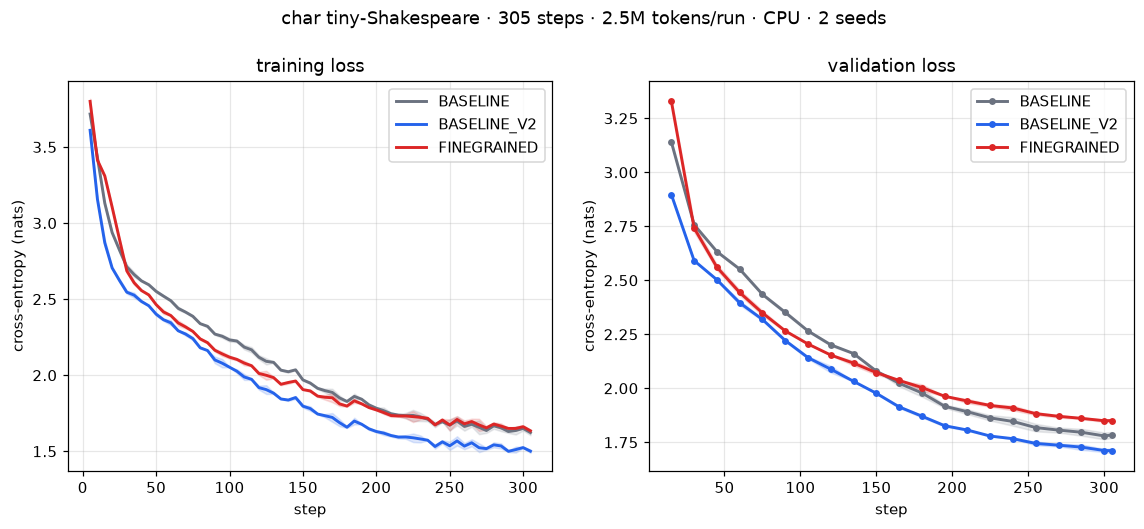

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
for name in VARIANTS:
    c = COLORS[name]
    tl = _stack([r["train_loss"] for r in runs[name]])
    steps = np.array(runs[name][0]["steps"])[:tl.shape[1]]
    axes[0].plot(steps, tl.mean(0), color=c, lw=1.9, label=name)
    axes[0].fill_between(steps, tl.min(0), tl.max(0), color=c, alpha=0.15)

    vl = _stack([r["val_loss"] for r in runs[name]])
    es = np.array(runs[name][0]["eval_steps"])[:vl.shape[1]]
    axes[1].plot(es, vl.mean(0), color=c, lw=1.9, marker="o", ms=3.5, label=name)
    axes[1].fill_between(es, vl.min(0), vl.max(0), color=c, alpha=0.15)

axes[0].set_title("training loss")
axes[1].set_title("validation loss")
for ax in axes:
    ax.set_xlabel("step"); ax.set_ylabel("cross-entropy (nats)"); ax.legend()
fig.suptitle(f"char tiny-Shakespeare · {STEPS} steps · {TOTAL_TOKENS/1e6:.1f}M tokens/run · "
             f"CPU · 2 seeds", y=1.02)
fig.savefig(FIG_DIR / "loss_curves.png")
plt.show()

## 6. Training diagnostics — perplexity, gradient norm, LR, aux loss

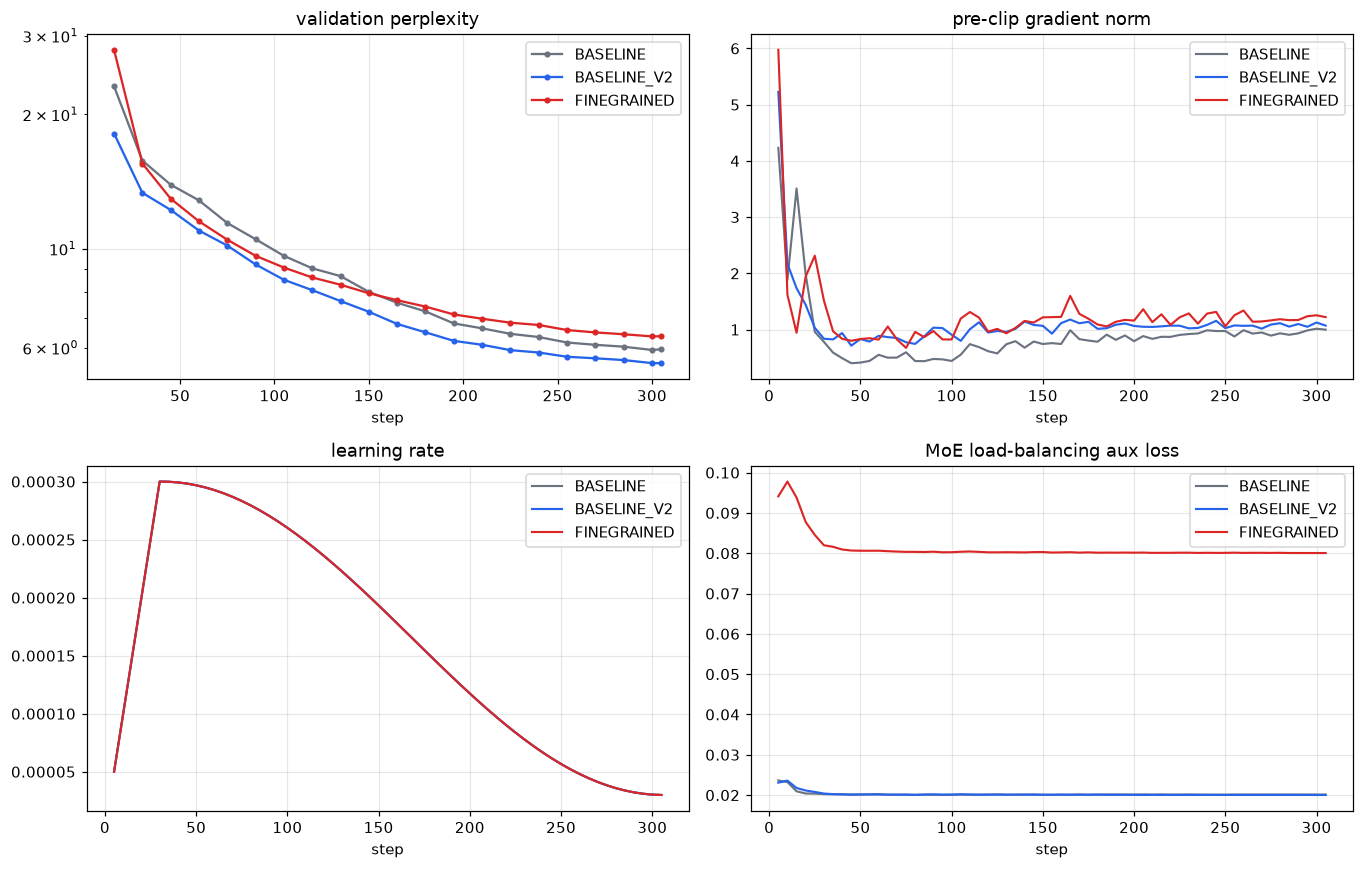

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12.5, 8))
for name in VARIANTS:
    c = COLORS[name]
    vp = _stack([r["val_perplexity"] for r in runs[name]]).mean(0)
    gn = _stack([r["grad_norm"] for r in runs[name]]).mean(0)
    aux = _stack([[a if a is not None else np.nan for a in r["aux_loss"]]
                  for r in runs[name]]).mean(0)
    lr = np.array(runs[name][0]["lr"])[:len(gn)]
    steps = np.array(runs[name][0]["steps"])[:len(gn)]
    es = np.array(runs[name][0]["eval_steps"])[:len(vp)]
    axes[0, 0].plot(es, vp, color=c, marker="o", ms=3, label=name)
    axes[0, 1].plot(steps, gn, color=c, lw=1.4, label=name)
    axes[1, 0].plot(steps, lr, color=c, lw=1.4, label=name)
    axes[1, 1].plot(steps, aux, color=c, lw=1.4, label=name)
axes[0, 0].set_title("validation perplexity"); axes[0, 0].set_yscale("log")
axes[0, 1].set_title("pre-clip gradient norm")
axes[1, 0].set_title("learning rate")
axes[1, 1].set_title("MoE load-balancing aux loss")
for ax in axes.flat:
    ax.set_xlabel("step"); ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "training_diagnostics.png")
plt.show()

## 7. Expert utilization

Per-routed-expert share of dispatched tokens, from the **final** training
step's `expert_token_counts` (seed 1337). Bars are per layer; the dashed line
is the perfectly-balanced share `1/n_experts`. `load CV` is the mean (over
layers) coefficient of variation of the per-expert load — lower is more
balanced. `routing entropy` is the mean per-layer Shannon entropy of the load
distribution divided by `log(n_experts)` — 1.0 is perfectly uniform.

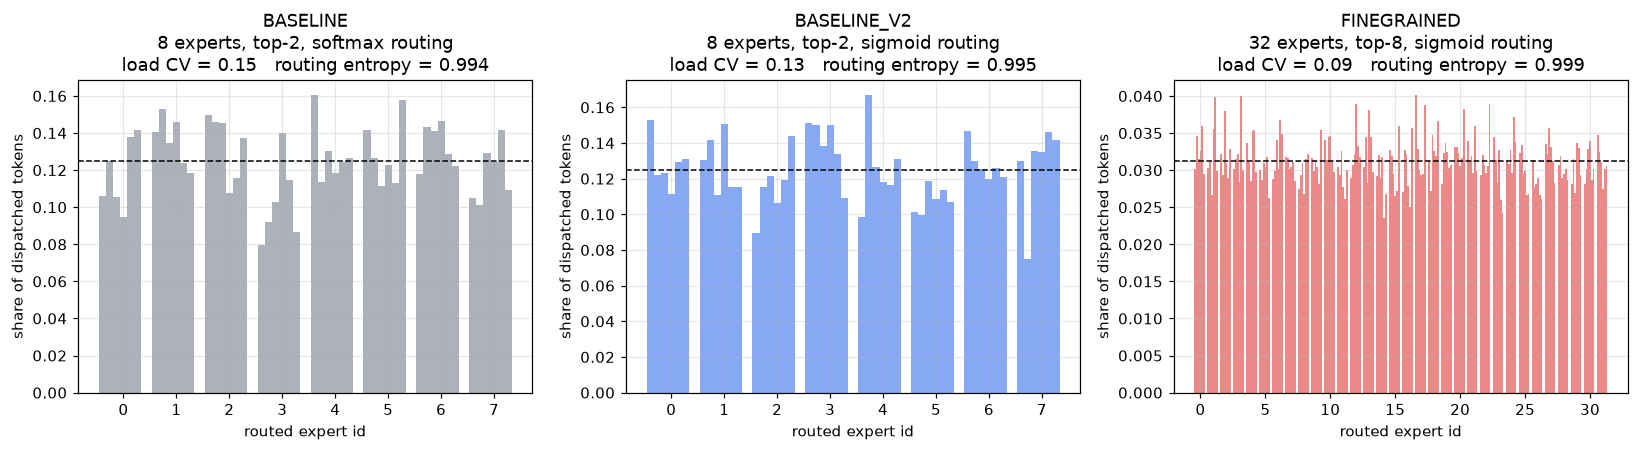

BASELINE      load CV=0.145  routing entropy=0.994
BASELINE_V2   load CV=0.133  routing entropy=0.995
FINEGRAINED   load CV=0.095  routing entropy=0.999


In [8]:
def balance_stats(counts):
    counts = np.asarray(counts, dtype=float)          # (n_layers, n_experts)
    frac = counts / counts.sum(1, keepdims=True)
    n_exp = frac.shape[1]
    cv = (frac.std(1) / (1.0 / n_exp)).mean()
    ent = -(frac * np.log(np.clip(frac, 1e-12, None))).sum(1) / math.log(n_exp)
    return frac, cv, ent.mean()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, name in zip(axes, VARIANTS):
    counts = runs[name][0]["final_expert_counts"]
    frac, cv, ent = balance_stats(counts)
    n_layers, n_exp = frac.shape
    width = 0.8 / n_layers
    for L in range(n_layers):
        ax.bar(np.arange(n_exp) + (L - n_layers/2) * width, frac[L], width,
               alpha=0.55, color=COLORS[name])
    ax.axhline(1.0 / n_exp, ls="--", color="k", lw=1)
    cfg = cfgs[name]
    ax.set_title(f"{name}\n{n_exp} experts, top-{cfg.top_k}, {cfg.router_scoring} routing\n"
                 f"load CV = {cv:.2f}   routing entropy = {ent:.3f}")
    ax.set_xlabel("routed expert id"); ax.set_ylabel("share of dispatched tokens")
fig.tight_layout()
fig.savefig(FIG_DIR / "expert_utilization.png")
plt.show()

for name in VARIANTS:
    _, cv, ent = balance_stats(runs[name][0]["final_expert_counts"])
    print(f"{name:<13} load CV={cv:.3f}  routing entropy={ent:.3f}")

## 8. Trace — QK-norm and the attention-logit scale

Journal [022](../journey_of_a_model/022-qk-norm.md) measured that without
QK-norm the pre-softmax attention logits' spread grows with the residual-stream
norm (and therefore with depth); with per-head RMSNorm on q and k it stays
bounded. Here we pull a real forward-pass trace
(`QwenMoEModel.forward_with_trace`, the same path every trace consumer uses) from
each trained checkpoint and read the standard deviation of
`attn_scores_pre_mask` layer by layer.

prompt tokens: 42


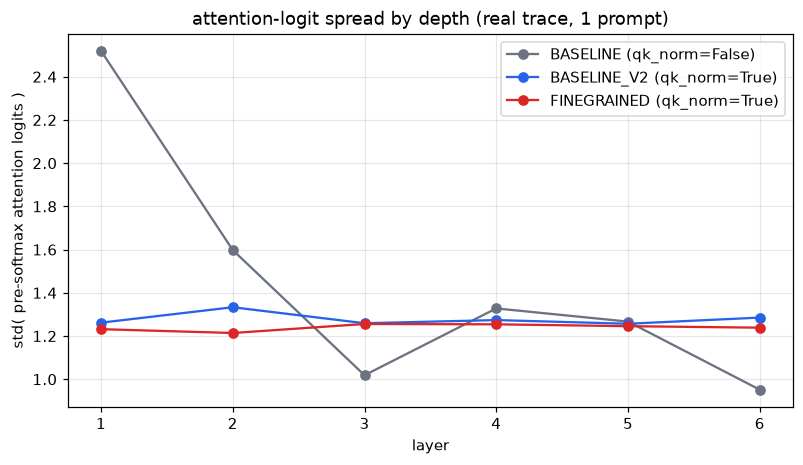

BASELINE      per-layer logit std [2.519, 1.598, 1.019, 1.328, 1.267, 0.952]  |  max|logit| 13.04
BASELINE_V2   per-layer logit std [1.262, 1.333, 1.259, 1.274, 1.257, 1.285]  |  max|logit| 5.73
FINEGRAINED   per-layer logit std [1.232, 1.214, 1.256, 1.254, 1.246, 1.239]  |  max|logit| 5.58


In [9]:
PROMPT = "ROMEO:\nWhat is the cause of this?\nJULIET:\n"
traces = {}
for name in VARIANTS:
    ckpt = RUN_DIR / name / f"seed_{SEEDS[0]}" / "checkpoints" / f"step_{STEPS}.pt"
    traces[name] = capture_trace(ckpt, PROMPT)
print("prompt tokens:", len(traces['BASELINE'].token_ids))

fig, ax = plt.subplots(figsize=(8.5, 4.4))
for name in VARIANTS:
    b = traces[name]
    stds = [layer.attn_scores_pre_mask.std().item() for layer in b.layers]
    ax.plot(range(1, len(stds) + 1), stds, marker="o", color=COLORS[name],
            label=f"{name} (qk_norm={cfgs[name].qk_norm})")
ax.set_xlabel("layer"); ax.set_ylabel("std( pre-softmax attention logits )")
ax.set_title("attention-logit spread by depth (real trace, 1 prompt)")
ax.legend()
fig.savefig(FIG_DIR / "attn_logit_scale.png")
plt.show()

for name in VARIANTS:
    b = traces[name]
    stds = [round(layer.attn_scores_pre_mask.std().item(), 3) for layer in b.layers]
    absmax = round(max(layer.attn_scores_pre_mask.abs().max().item() for layer in b.layers), 2)
    print(f"{name:<13} per-layer logit std {stds}  |  max|logit| {absmax}")

## 9. Trace — routing decisions on one prompt

Layer-0 top-k expert picks and gate weights for the first few prompt tokens,
plus the mean normalized entropy of the full router distribution.

In [10]:
for name in VARIANTS:
    b = traces[name]
    L0 = b.layers[0]
    cfg = cfgs[name]
    print(f"--- {name}  ({cfg.n_routed_experts} experts, top-{cfg.top_k}, {cfg.router_scoring}) ---")
    for t in range(min(5, len(b.token_ids))):
        idx = L0.topk_indices[t].tolist()
        w = [round(x, 3) for x in L0.topk_weights[t].tolist()]
        print(f"   token {t}: experts {idx}  gate weights {w}  (Σ={sum(w):.3f})")
    p = L0.router_probs
    ent = (-(p * p.clamp_min(1e-9).log()).sum(-1) / math.log(p.shape[-1])).mean().item()
    # per-layer routing entropy
    per_layer = []
    for layer in b.layers:
        q = layer.router_probs
        per_layer.append(round((-(q * q.clamp_min(1e-9).log()).sum(-1)
                                 / math.log(q.shape[-1])).mean().item(), 3))
    print(f"   layer-0 mean normalized router entropy: {ent:.3f}")
    print(f"   per-layer router entropy: {per_layer}\n")

--- BASELINE  (8 experts, top-2, softmax) ---
   token 0: experts [0, 4]  gate weights [0.522, 0.478]  (Σ=1.000)
   token 1: experts [0, 4]  gate weights [0.628, 0.372]  (Σ=1.000)
   token 2: experts [0, 4]  gate weights [0.615, 0.385]  (Σ=1.000)
   token 3: experts [0, 4]  gate weights [0.602, 0.398]  (Σ=1.000)
   token 4: experts [0, 4]  gate weights [0.639, 0.361]  (Σ=1.000)
   layer-0 mean normalized router entropy: 0.947
   per-layer router entropy: [0.947, 0.968, 0.961, 0.94, 0.931, 0.946]

--- BASELINE_V2  (8 experts, top-2, sigmoid) ---
   token 0: experts [4, 0]  gate weights [0.526, 0.474]  (Σ=1.000)
   token 1: experts [0, 4]  gate weights [0.513, 0.487]  (Σ=1.000)
   token 2: experts [0, 4]  gate weights [0.502, 0.498]  (Σ=1.000)
   token 3: experts [4, 0]  gate weights [0.512, 0.488]  (Σ=1.000)
   token 4: experts [4, 0]  gate weights [0.501, 0.499]  (Σ=1.000)
   layer-0 mean normalized router entropy: 0.977
   per-layer router entropy: [0.977, 0.982, 0.978, 0.978, 0.979, 

## 10. Results summary

In [11]:
results = {
    "config": {
        "corpus": "tiny_shakespeare", "tokenizer": "char", "vocab_size": VOCAB,
        "fixed_slice_tokens": data_config.fixed_slice_tokens,
        "batch_size": BATCH, "seq_len": SEQ, "total_tokens": TOTAL_TOKENS,
        "steps": STEPS, "seeds": list(SEEDS), "device": "cpu",
        "lr": 3e-4, "lr_schedule": "cosine", "warmup_steps": 30,
    },
    "variants": {},
}
for name in VARIANTS:
    cfg, bd = param_row(name, VOCAB)
    _, bd_bpe = param_row(name, 4096)
    s = summary[name]
    results["variants"][name] = {
        "params_total": bd.total, "params_active": bd.active,
        "params_total_bpe4096": bd_bpe.total, "params_active_bpe4096": bd_bpe.active,
        "val_loss_mean": s["val_loss_mean"], "val_loss_std": s["val_loss_std"],
        "val_ppl_mean": s["val_ppl_mean"], "val_ppl_std": s["val_ppl_std"],
        "train_loss_mean": s["train_loss_mean"],
        "delta_val_loss_vs_baseline": s["delta_vs_baseline"],
        "within_seed_noise": s["within_noise"],
        "tokens_per_sec_cpu": s["tokens_per_sec"],
        "per_seed_val_loss": [r["val_loss"][-1] for r in runs[name]],
    }

out = RUN_DIR / "results.json"
out.write_text(json.dumps(results, indent=2))
print("wrote", out, "\n")
print(json.dumps(results, indent=2))

wrote /Users/sjoseph/Documents/Study/training-my-moe/runs/modernized_presets/results.json 

{
  "config": {
    "corpus": "tiny_shakespeare",
    "tokenizer": "char",
    "vocab_size": 65,
    "fixed_slice_tokens": 1000000,
    "batch_size": 32,
    "seq_len": 256,
    "total_tokens": 2500000,
    "steps": 305,
    "seeds": [
      1337,
      2024
    ],
    "device": "cpu",
    "lr": 0.0003,
    "lr_schedule": "cosine",
    "warmup_steps": 30
  },
  "variants": {
    "BASELINE": {
      "params_total": 22445568,
      "params_active": 8289792,
      "params_total_bpe4096": 23477504,
      "params_active_bpe4096": 9321728,
      "val_loss_mean": 1.7835704803466796,
      "val_loss_std": 0.019320283944787867,
      "val_ppl_mean": 5.951622049621219,
      "val_ppl_std": 0.11497987486548165,
      "train_loss_mean": 1.6228759288787842,
      "delta_val_loss_vs_baseline": 0.0,
      "within_seed_noise": null,
      "tokens_per_sec_cpu": 10250.271354876408,
      "per_seed_val_loss": [
  

## 11. Takeaways

See journal entry
[035-modernized-presets-training-run.md](../journey_of_a_model/035-modernized-presets-training-run.md)
for the narrated interpretation. In short, this notebook produces:

- `journey_of_a_model/figures/035/loss_curves.png`
- `journey_of_a_model/figures/035/training_diagnostics.png`
- `journey_of_a_model/figures/035/expert_utilization.png`
- `journey_of_a_model/figures/035/attn_logit_scale.png`
- `runs/modernized_presets/results.json`

and the per-variant checkpoints + logs under `runs/modernized_presets/`.